# Retail360: de los datos a las decisiones comerciales
### Análisis comercial de tres productos de un comercio electrónico
**ADMI 1301 — Introducción a la Programación**  
Pablo Gómez y Juan Sebastián Pineda | Opción B

## 1. Contexto y objetivo
**Pregunta:** ¿qué producto de los tres seleccionados conviene priorizar comercialmente según sus ingresos, volumen, evolución mensual y comportamiento de compra durante el primer trimestre de 2011?

El análisis está dirigido al área de ventas o mercadeo. Usamos los mismos 1.334 registros de la primera entrega, correspondientes al Reino Unido, entre enero y marzo de 2011. La fuente original es [Online Retail — UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/352/online+retail). La selección excluye cancelaciones y cantidades o precios no positivos. Todos los ingresos se expresan en libras esterlinas (GBP).

**Ruta del análisis:** revisar la base → preparar los datos → comparar productos → estudiar los cambios mensuales, las facturas y los clientes → consultar el panel → comprobar resultados y recomendar acciones.

**Cómo ejecutar**
1. Abrir `Proyecto_ADMI_1301.ipynb` en Google Colab y subir `Base_de_datos.xlsx` desde el panel de archivos (icono de carpeta). En Jupyter, guardar ambos archivos en la misma carpeta.
2. Seleccionar **Entorno de ejecución → Ejecutar todas**. Se necesitan Pandas, Matplotlib y el lector de Excel (openpyxl, normalmente disponible en Colab).
3. En la sección 7, cambiar los filtros y volver a ejecutar únicamente la celda del panel.

El Excel es la base original; el notebook no lo modifica ni requiere descargar la base completa de UCI.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Cargar la base de la primera entrega.
datos = pd.read_excel("Base_de_datos.xlsx")
print("Registros:", datos.shape[0])
print("Columnas:", datos.shape[1])
datos.head()

Registros: 1334
Columnas: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,539993,85123A,WHITE HANGING HEART T-LIGHT HOLDER,12,2011-01-04 10:00:00,2.95,13313.0,United Kingdom
1,540003,22720,SET OF 3 CAKE TINS PANTRY DESIGN,3,2011-01-04 10:37:00,4.95,16875.0,United Kingdom
2,540014,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2011-01-04 11:34:00,2.95,14606.0,United Kingdom
3,540014,22423,REGENCY CAKESTAND 3 TIER,1,2011-01-04 11:34:00,12.75,14606.0,United Kingdom
4,540015,22720,SET OF 3 CAKE TINS PANTRY DESIGN,6,2011-01-04 11:40:00,4.95,13319.0,United Kingdom


## 2. Revisión de la base
Revisamos los datos faltantes, las filas idénticas, las fechas, el país y los productos. Una fila es un registro de venta; una factura puede contener varias filas.

In [2]:
datos.info()
print("Datos faltantes:")
print(datos.isna().sum())
print("Filas idénticas adicionales:", datos.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1334 entries, 0 to 1333
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    1334 non-null   int64         
 1   StockCode    1334 non-null   object        
 2   Description  1334 non-null   object        
 3   Quantity     1334 non-null   int64         
 4   InvoiceDate  1334 non-null   datetime64[ns]
 5   UnitPrice    1334 non-null   float64       
 6   CustomerID   1140 non-null   float64       
 7   Country      1334 non-null   object        
dtypes: datetime64[ns](1), float64(2), int64(2), object(3)
memory usage: 83.5+ KB
Datos faltantes:
InvoiceNo        0
StockCode        0
Description      0
Quantity         0
InvoiceDate      0
UnitPrice        0
CustomerID     194
Country          0
dtype: int64
Filas idénticas adicionales: 6


In [3]:
datos["InvoiceDate"] = pd.to_datetime(datos["InvoiceDate"])
print("País:", datos["Country"].unique())
print("Productos:", datos["StockCode"].unique())
print("Primera fecha:", datos["InvoiceDate"].min())
print("Última fecha:", datos["InvoiceDate"].max())
print("Cantidades no positivas:", len(datos[datos["Quantity"] <= 0]))
print("Precios no positivos:", len(datos[datos["UnitPrice"] <= 0]))

País: ['United Kingdom']
Productos: ['85123A' '22720' '22423']
Primera fecha: 2011-01-04 10:00:00
Última fecha: 2011-03-31 19:54:00
Cantidades no positivas: 0
Precios no positivos: 0


## 3. Preparación de los datos
Usamos diccionarios y `map()` para asignar nombres cortos a los productos y meses. Multiplicamos cantidad por precio unitario para obtener el ingreso de cada registro. Los códigos de producto permanecen en la base.

Para facilitar la lectura, cada producto conserva el mismo color en todas las gráficas. Los meses se presentan en orden cronológico.

In [4]:
nombres = {"85123A": "Portavelas", "22720": "Juego de latas", "22423": "Soporte para tortas"}
meses = {1: "Enero", 2: "Febrero", 3: "Marzo"}
colores = {"Soporte para tortas": "#245A81", "Portavelas": "#16877F", "Juego de latas": "#B86B28"}

datos["Producto"] = datos["StockCode"].map(nombres)
datos["Mes"] = datos["InvoiceDate"].dt.month.map(meses)
datos["Ingreso"] = datos["Quantity"] * datos["UnitPrice"]

datos[["Producto", "Mes", "Quantity", "UnitPrice", "Ingreso"]].head()

,Producto,Mes,Quantity,UnitPrice,Ingreso
0,Portavelas,Enero,12,2.95,35.40
1,Juego de latas,Enero,3,4.95,14.85
2,Portavelas,Enero,6,2.95,17.70
3,Soporte para tortas,Enero,1,12.75,12.75
4,Juego de latas,Enero,6,4.95,29.70


In [5]:
total_ingresos = datos["Ingreso"].sum()
total_unidades = datos["Quantity"].sum()

print("Ingresos (GBP):", round(total_ingresos, 2))
print("Unidades:", total_unidades)
print("Facturas distintas:", datos["InvoiceNo"].nunique())
print("Clientes identificados:", datos["CustomerID"].nunique())

# Medir el efecto de eliminar filas idénticas sin alterar la base.
sin_duplicados = datos.drop_duplicates()
diferencia = total_ingresos - sin_duplicados["Ingreso"].sum()
print("Ingresos sin filas idénticas (GBP):", round(sin_duplicados["Ingreso"].sum(), 2))
print("Diferencia (GBP):", round(diferencia, 2))
print("Impacto sobre ingresos (%):", round(diferencia / total_ingresos * 100, 2))
print("Registros sin cliente (%):", round(datos["CustomerID"].isna().sum() / len(datos) * 100, 2))

Ingresos (GBP): 66428.7
Unidades: 13154
Facturas distintas: 1059
Clientes identificados: 675
Ingresos sin filas idénticas (GBP): 66388.35
Diferencia (GBP): 40.35
Impacto sobre ingresos (%): 0.06
Registros sin cliente (%): 14.54


Hay 194 registros sin identificador de cliente (14,54%): se conservan para calcular ventas, pero no para estudiar recurrencia. También conservamos las seis filas idénticas adicionales porque no sabemos si son errores o líneas de compra registradas por separado. Quitarlas reduciría el ingreso de £66.428,70 a £66.388,35: una diferencia de £40,35 (0,06%). Esta comparación hace transparente el efecto de la decisión de limpieza. No modificamos el Excel original. Hablamos de ingresos brutos de la selección, no de ganancias ni ingresos netos.

## 4. Comparación por producto
`groupby()` reúne los registros por producto. `sum()` suma sus ventas y unidades; `nunique()` cuenta facturas o clientes distintos. Dividimos los ingresos por el total para obtener su participación, y por las unidades para obtener el precio promedio ponderado.

In [6]:
ingresos = datos.groupby("Producto")["Ingreso"].sum()
unidades = datos.groupby("Producto")["Quantity"].sum()
facturas = datos.groupby("Producto")["InvoiceNo"].nunique()
clientes = datos.groupby("Producto")["CustomerID"].nunique()

resumen = pd.DataFrame()
resumen["Ingresos (GBP)"] = ingresos
resumen["Unidades"] = unidades
resumen["Facturas"] = facturas
resumen["Clientes identificados"] = clientes
resumen["Participación ingresos (%)"] = ingresos / total_ingresos * 100
resumen["Participación unidades (%)"] = unidades / total_unidades * 100
resumen["Precio promedio (GBP)"] = ingresos / unidades
resumen["Ingreso por factura (GBP)"] = ingresos / facturas

resumen = resumen.sort_values("Ingresos (GBP)", ascending=False)
resumen.round(2)

,Ingresos (GBP),Unidades,Facturas,Clientes identificados,Participación ingresos (%),Participación unidades (%),Precio promedio (GBP),Ingreso por factura (GBP)
Producto,,,,,,,,
Soporte para tortas,33201.14,2593,397,254,49.98,19.71,12.80,83.63
Portavelas,24541.12,8874,475,335,36.94,67.46,2.77,51.67
Juego de latas,8686.44,1687,435,295,13.08,12.82,5.15,19.97


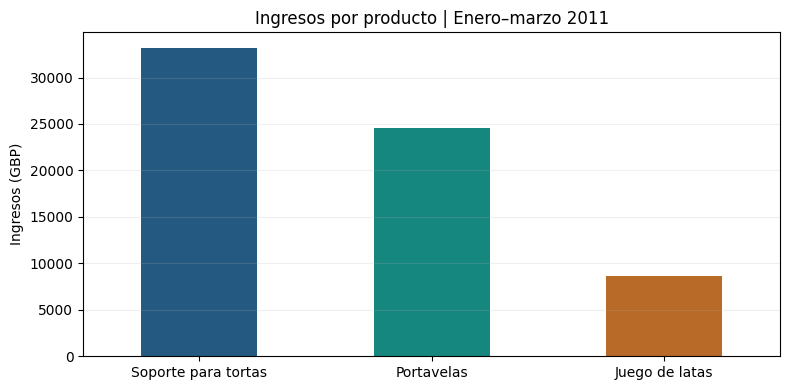

In [7]:
resumen["Ingresos (GBP)"].plot.bar(figsize=(8, 4), color=resumen.index.map(colores))
plt.title("Ingresos por producto | Enero–marzo 2011")
plt.xlabel("")
plt.ylabel("Ingresos (GBP)")
plt.xticks(rotation=0)
plt.ylim(bottom=0)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

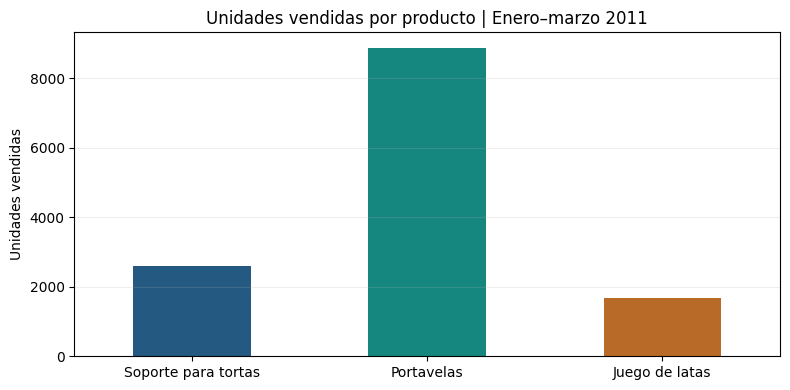

In [8]:
resumen["Unidades"].plot.bar(figsize=(8, 4), color=resumen.index.map(colores))
plt.title("Unidades vendidas por producto | Enero–marzo 2011")
plt.xlabel("")
plt.ylabel("Unidades vendidas")
plt.xticks(rotation=0)
plt.ylim(bottom=0)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

**Hallazgo:** el soporte para tortas lidera los ingresos (£33.201,14), con el 49,98% del total y solo el 19,71% de las unidades. El portavelas concentra el 67,46% de las unidades, pero el 36,94% de los ingresos. El precio promedio ponderado del soporte es £12,80 y el del portavelas £2,77. Por eso el producto que más unidades vende no necesariamente genera más ingresos. El ingreso por factura se calcula para las facturas que contienen cada producto y solo incluye las líneas de ese producto; no equivale al valor total de una cesta de compra.

## 5. Evolución mensual
Con `pivot_table()` organizamos los datos: filas por mes, columnas por producto y suma de ingresos o unidades. Ordenamos los meses cronológicamente.

In [9]:
ingresos_mes = datos.pivot_table(index="Mes", columns="Producto", values="Ingreso", aggfunc="sum")
ingresos_mes = ingresos_mes.loc[["Enero", "Febrero", "Marzo"]]
print(ingresos_mes.round(2))

unidades_mes = datos.pivot_table(index="Mes", columns="Producto", values="Quantity", aggfunc="sum")
unidades_mes = unidades_mes.loc[["Enero", "Febrero", "Marzo"]]
print(unidades_mes)

print("\nIngresos totales por mes (GBP):")
print(ingresos_mes.sum(axis=1).round(2))

Producto  Juego de latas  Portavelas  Soporte para tortas
Mes                                                      
Enero            2547.32    14464.21              8429.60
Febrero          2741.17     4709.11              8438.64
Marzo            3397.95     5367.80             16332.90
Producto  Juego de latas  Portavelas  Soporte para tortas
Mes                                                      
Enero                511        5241                  648
Febrero              531        1713                  670
Marzo                645        1920                 1275

Ingresos totales por mes (GBP):
Mes
Enero      25441.13
Febrero    15888.92
Marzo      25098.65
dtype: float64


Para calcular el crecimiento, restamos el ingreso del mes anterior al actual y dividimos esa diferencia por el ingreso del mes anterior. Multiplicamos por 100 para expresarlo como porcentaje.

In [10]:
enero = ingresos_mes.loc["Enero"]
febrero = ingresos_mes.loc["Febrero"]
marzo = ingresos_mes.loc["Marzo"]

variacion = pd.DataFrame()
variacion["Enero a febrero (%)"] = (febrero - enero) / enero * 100
variacion["Febrero a marzo (%)"] = (marzo - febrero) / febrero * 100
print(variacion.round(2))

cambio_febrero = (febrero.sum() - enero.sum()) / enero.sum() * 100
cambio_marzo = (marzo.sum() - febrero.sum()) / febrero.sum() * 100
print("Variación total febrero (%):", round(cambio_febrero, 2))
print("Variación total marzo (%):", round(cambio_marzo, 2))

                     Enero a febrero (%)  Febrero a marzo (%)
Producto                                                     
Juego de latas                      7.61                23.96
Portavelas                        -67.44                13.99
Soporte para tortas                 0.11                93.55
Variación total febrero (%): -37.55
Variación total marzo (%): 57.96


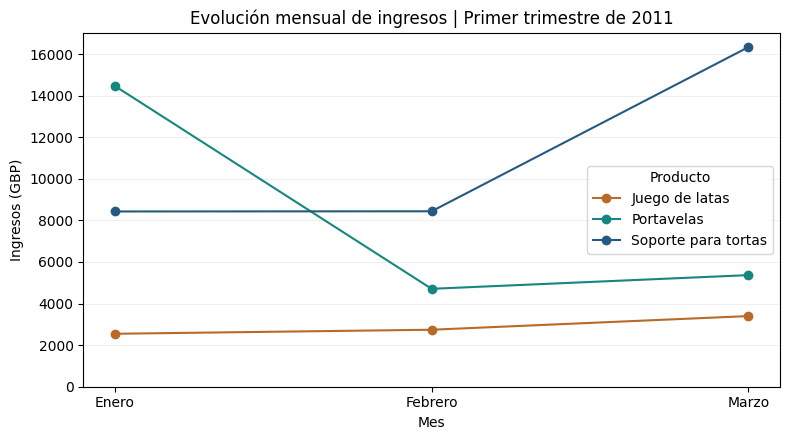

In [11]:
ingresos_mes.plot.line(figsize=(8, 4.5), marker="o", color=[colores["Juego de latas"], colores["Portavelas"], colores["Soporte para tortas"]])
plt.title("Evolución mensual de ingresos | Primer trimestre de 2011")
plt.xlabel("Mes")
plt.ylabel("Ingresos (GBP)")
plt.xticks([0, 1, 2], ["Enero", "Febrero", "Marzo"])
plt.ylim(bottom=0)
plt.grid(axis="y", alpha=0.2)
plt.legend(title="Producto")
plt.tight_layout()
plt.show()

Los ingresos totales disminuyeron 37,55% en febrero y se recuperaron 57,96% en marzo. El soporte para tortas creció 93,55% entre febrero y marzo. El juego de latas aumentó sus ingresos en ambos cambios mensuales (+7,61% y +23,96%). El portavelas cayó 67,44% en febrero y se recuperó parcialmente en marzo (+13,99%). Tres meses no permiten concluir que exista estacionalidad.

## 6. Facturas y clientes
### Compras grandes
Agrupamos por producto y número de factura para reunir las líneas de una misma compra. Luego usamos `max()` para encontrar el ingreso más alto de un producto dentro de una factura y calculamos cuánto representa del ingreso trimestral de ese artículo.

Como comprobación adicional, calculamos los ingresos de cada producto si se excluyera su mayor factura. Es un escenario ilustrativo para entender su exposición a pedidos grandes, no una corrección de los ingresos reales.

In [12]:
por_factura = datos.groupby(["Producto", "InvoiceNo"])["Ingreso"].sum().reset_index()
mayor_factura = por_factura.groupby("Producto")["Ingreso"].max()

concentracion = pd.DataFrame()
concentracion["Mayor factura (GBP)"] = mayor_factura
concentracion["Participación (%)"] = mayor_factura / ingresos * 100
concentracion["Ingresos sin mayor factura (GBP)"] = ingresos - mayor_factura
concentracion = concentracion.sort_values("Participación (%)", ascending=False)
print(concentracion.round(2))

por_factura.sort_values("Ingreso", ascending=False).head(5)

                     Mayor factura (GBP)  Participación (%)  \
Producto                                                      
Portavelas                        4921.5              20.05   
Soporte para tortas               1642.5               4.95   
Juego de latas                     259.0               2.98   

                     Ingresos sin mayor factura (GBP)  
Producto                                               
Portavelas                                   19619.62  
Soporte para tortas                          31558.64  
Juego de latas                                8427.44  


,Producto,InvoiceNo,Ingreso
488,Portavelas,540815,4921.50
482,Portavelas,540689,3272.40
1140,Soporte para tortas,545341,1642.50
1071,Soporte para tortas,543976,788.40
1262,Soporte para tortas,547788,673.92


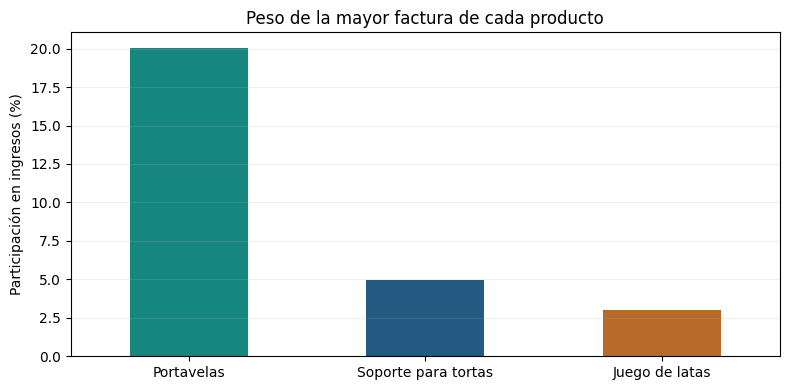

In [13]:
concentracion["Participación (%)"].plot.bar(figsize=(8, 4), color=concentracion.index.map(colores))
plt.title("Peso de la mayor factura de cada producto")
plt.xlabel("")
plt.ylabel("Participación en ingresos (%)")
plt.xticks(rotation=0)
plt.ylim(bottom=0)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

La mayor factura de portavelas generó £4.921,50, equivalente al 20,05% de sus ingresos del trimestre. La mayor factura de soportes representa 4,95% y la de latas 2,98%. Sin su mayor factura, los ingresos del portavelas serían £19.619,62, frente a £31.558,64 para el soporte sin su propia mayor factura. El soporte conserva el liderazgo en esta comparación. El portavelas está más expuesto a su mayor pedido observado; no conviene asumir que su pico de enero sea demanda habitual.

### Clientes recurrentes
Excluimos los registros sin identificador únicamente de este análisis. Contamos las facturas distintas de cada cliente. Consideramos recurrente a quien aparece en dos o más facturas de la selección.

In [14]:
identificados = datos.dropna(subset=["CustomerID"])
compras_cliente = identificados.groupby("CustomerID")["InvoiceNo"].nunique()
recurrentes = compras_cliente[compras_cliente >= 2]
porcentaje = len(recurrentes) / len(compras_cliente) * 100

print("Clientes identificados:", len(compras_cliente))
print("Clientes recurrentes:", len(recurrentes))
print("Porcentaje recurrente:", round(porcentaje, 2))
print("Registros con cliente identificado (%):", round(len(identificados) / len(datos) * 100, 2))

Clientes identificados: 675
Clientes recurrentes: 161
Porcentaje recurrente: 23.85
Registros con cliente identificado (%): 85.46


También podemos repetir el mismo cálculo para cada producto con un ciclo `for`. Un cliente puede comprar más de un producto; por eso los clientes de cada artículo no se deben sumar para obtener los clientes totales.

In [15]:
for producto in datos["Producto"].unique():
    ventas_producto = identificados[identificados["Producto"] == producto]
    compras = ventas_producto.groupby("CustomerID")["InvoiceNo"].nunique()
    repetidos = compras[compras >= 2]
    print(producto)
    print("Clientes:", len(compras))
    print("Recurrentes:", len(repetidos))
    print("Porcentaje:", round(len(repetidos) / len(compras) * 100, 2))
    print()

Portavelas
Clientes: 335
Recurrentes: 62
Porcentaje: 18.51

Juego de latas
Clientes: 295
Recurrentes: 56
Porcentaje: 18.98

Soporte para tortas
Clientes: 254
Recurrentes: 48
Porcentaje: 18.9



De los 675 clientes identificados, 161 (23,85%) realizaron compras en dos o más facturas de la selección. El 85,46% de los registros contiene identificador de cliente. Los porcentajes por producto son similares (entre 18,51% y 18,98%), por lo que la recurrencia observada no muestra una diferencia marcada entre ellos. No es una medida de retención de toda la tienda: solo analizamos tres artículos, durante tres meses, y algunos registros no tienen identificador.

## 7. Panel de consulta
El formulario permite escoger un mes, un producto y un indicador, como en la clase 25. Usamos condicionales `if` para filtrar. Al cambiar una opción, volvemos a ejecutar esta celda. En Jupyter se pueden editar las tres variables directamente.

El panel muestra los ingresos, unidades, facturas distintas y clientes identificados de la selección. El indicador cambia la gráfica; los cuatro indicadores numéricos se mantienen disponibles. **Todos** muestra el trimestre completo o los tres productos, según el filtro.

Periodo: Todos | Producto: Todos
Registros: 1334
Ingresos (GBP): 66428.7
Unidades: 13154
Facturas distintas: 1059
Clientes identificados: 675


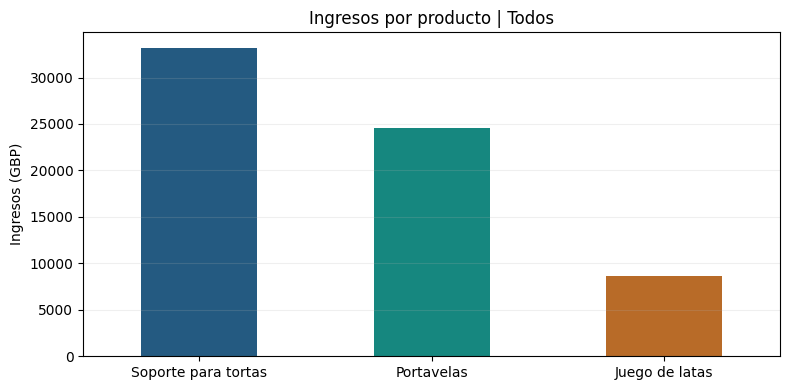

In [16]:
#@title Retail360 | Panel de ventas { display-mode: "form" }
mes = "Todos" #@param ["Todos", "Enero", "Febrero", "Marzo"]
producto = "Todos" #@param ["Todos", "Soporte para tortas", "Portavelas", "Juego de latas"]
indicador = "Ingresos" #@param ["Ingresos", "Unidades"]

seleccion = datos.copy()
if mes != "Todos":
    seleccion = seleccion[seleccion["Mes"] == mes]
if producto != "Todos":
    seleccion = seleccion[seleccion["Producto"] == producto]

print("Periodo:", mes, "| Producto:", producto)
print("Registros:", len(seleccion))
print("Ingresos (GBP):", round(seleccion["Ingreso"].sum(), 2))
print("Unidades:", seleccion["Quantity"].sum())
print("Facturas distintas:", seleccion["InvoiceNo"].nunique())
print("Clientes identificados:", seleccion["CustomerID"].nunique())

if indicador == "Ingresos":
    columna = "Ingreso"
    eje = "Ingresos (GBP)"
else:
    columna = "Quantity"
    eje = "Unidades vendidas"

resultado = seleccion.groupby("Producto")[columna].sum().sort_values(ascending=False)
resultado.plot.bar(figsize=(8, 4), color=resultado.index.map(colores))
plt.title(indicador + " por producto | " + mes)
plt.xlabel("")
plt.ylabel(eje)
plt.xticks(rotation=0)
plt.ylim(bottom=0)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 8. Comprobación de resultados
Comprobamos que la selección conserva sus dimensiones, que todas las filas tienen producto y mes válidos, que cantidades y precios son positivos, y que los totales de las distintas agrupaciones coinciden. Redondeamos los ingresos a dos decimales antes de comparar. Cada control debe mostrar `True`.

In [17]:
print("Base original (1.334 registros):", len(datos) == 1334)
print("Solo Reino Unido:", len(datos[datos["Country"] != "United Kingdom"]) == 0)
print("Periodo enero–marzo de 2011:", datos["InvoiceDate"].min() >= pd.Timestamp("2011-01-01") and datos["InvoiceDate"].max() < pd.Timestamp("2011-04-01"))
print("Tres productos y sin códigos sin asignar:", datos["Producto"].nunique() == 3 and datos["Producto"].isna().sum() == 0)
print("Tres meses y sin meses sin asignar:", datos["Mes"].nunique() == 3 and datos["Mes"].isna().sum() == 0)
print("Cantidades positivas:", len(datos[datos["Quantity"] <= 0]) == 0 and datos["Quantity"].isna().sum() == 0)
print("Precios positivos:", len(datos[datos["UnitPrice"] <= 0]) == 0 and datos["UnitPrice"].isna().sum() == 0)
print("Ingresos por producto coinciden:", round(ingresos.sum(), 2) == round(total_ingresos, 2))
print("Ingresos por mes coinciden:", round(ingresos_mes.sum().sum(), 2) == round(total_ingresos, 2))
print("Ingresos por factura coinciden:", round(por_factura["Ingreso"].sum(), 2) == round(total_ingresos, 2))
print("Unidades por producto coinciden:", unidades.sum() == total_unidades)
print("Unidades por mes coinciden:", unidades_mes.sum().sum() == total_unidades)

Base original (1.334 registros): True
Solo Reino Unido: True
Periodo enero–marzo de 2011: True
Tres productos y sin códigos sin asignar: True
Tres meses y sin meses sin asignar: True
Cantidades positivas: True
Precios positivos: True
Ingresos por producto coinciden: True
Ingresos por mes coinciden: True
Ingresos por factura coinciden: True
Unidades por producto coinciden: True
Unidades por mes coinciden: True


## 9. Conclusiones y recomendaciones
**Respuesta a la pregunta inicial:** priorizar el seguimiento comercial del soporte para tortas. Es el producto con mayores ingresos del trimestre (£33.201,14), crece 93,55% de febrero a marzo y su mayor factura representa solo el 4,95% de sus ingresos. El liderazgo se mantiene incluso al excluir la mayor factura de cada producto. Esto lo convierte en la primera opción para estudiar una expansión comercial, aunque no prueba que sea el más rentable.

| Producto | Acción propuesta | Indicador para revisar |
|---|---|---|
| Soporte para tortas | Revisar costos, márgenes y existencias antes de aumentar compras o promoción. | Ingresos, margen e inventario. |
| Portavelas | Mantenerlo como producto de volumen y separar el seguimiento de pedidos grandes del resto de las compras. | Unidades y participación de la mayor factura. |
| Juego de latas | Probar acciones de mercadeo a pequeña escala y evaluar si continúa su crecimiento. | Variación mensual de ingresos y unidades. |

**Alcance y limitaciones:** el estudio cubre tres productos en Reino Unido durante tres meses. No disponemos de costos ni inventarios; las cancelaciones y devoluciones no forman parte de la selección. Por tanto, no podemos calcular rentabilidad, ingresos netos o estacionalidad. Los identificadores faltantes limitan el análisis de recurrencia. Los clientes y las facturas por producto pueden coincidir entre sí, por lo que sus conteos no se suman para obtener los totales generales.

**Próximo paso:** revisar los resultados mensualmente con el panel, ampliar el periodo y el catálogo, e incorporar costos e inventarios antes de tomar decisiones de inversión o abastecimiento.

**Fuente:** [Online Retail — UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/352/online+retail). Archivo analizado: `Base_de_datos.xlsx`, selección de la primera entrega.

**Nota de IA:** usamos ChatGPT como apoyo para organizar el análisis, simplificar el código y verificar resultados. Los integrantes deben ejecutar, revisar y comprender el notebook y sus conclusiones antes de la entrega.